# Telco Customer Churn — Exploratory Data Analysis

**Goal:** get familiar with the Telco Customer Churn dataset, check its data quality, and answer a set of concrete business questions about who churns and why.

**Dataset:** [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (loaded via the Kaggle API through `kagglehub`) — 7,043 customers of a fictional telecom company, with demographics, subscribed services, billing details, and whether they churned.

**What this notebook covers:**
1. Load the raw dataset
2. First look — shape, dtypes, sample rows, summary stats
3. Data quality checks — duplicates, missing values, hidden/placeholder missing values, categorical consistency
4. Feature engineering — tenure buckets, add-on count
5. Business question analysis (Q1–Q11)
6. Summary of findings

## Executive summary

- **Overall churn is 26.5%.** Contract type is the biggest driver: 43% of month-to-month customers churn, vs 11% (one-year) and 3% (two-year).
- **Highest-risk group:** month-to-month + internet + no add-ons → **53.6% churn**. 670 customers (9.5% of the base), ~$39K/month in billing. This group can be found early (Q11).
- **Electronic check** payers churn more than other payment methods in every contract type, so it is a separate risk factor (Q4). Paperless billing is also linked to higher churn, but probably overlaps with month-to-month contracts (Q5).
- **Open question:** fiber optic customers churn much more than DSL (42% vs 19%). This data can't show if the reason is price or service quality (Q7).
- **No effect:** gender and phone service (Q3, Q10).
- **Suggested action:** retention offers (contract-upgrade discount, free add-on trial, onboarding call) for new month-to-month customers with no add-ons.

*Data-quality checks, method and statistical tests below.*

In [1]:
import os
import kagglehub      
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid") 

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Plain-English label for p-values (0.05 is the usual significance threshold)
def p_label(p_value):
    if p_value < 0.001:
        return "(p < 0.001, significant)"
    elif p_value < 0.05:
        return "(p < 0.05, significant)"
    else:
        return "(not significant)"

print("Setup complete.")

Setup complete.


### Data source

Reference blog post describing this dataset in more detail: https://community.ibm.com/community/user/blogs/steven-macko/2019/07/11/telco-customer-churn-1113

## Data overview

Each row is one customer. Column meanings:

- **customerID**: A unique ID that identifies each customer.
- **gender**: The customer's gender: Male, Female.
- **SeniorCitizen**: Indicates if the customer is 65 or older: 1, 0.
- **Partner**: Indicates if the customer has a partner: Yes, No.
- **Dependents**: Indicates if the customer lives with any dependents (children, parents, etc.): Yes, No.
- **tenure** (in months): Total number of months the customer has been with the company.
- **PhoneService**: Indicates if the customer subscribes to home phone service: Yes, No.
- **MultipleLines**: Indicates if the customer subscribes to multiple telephone lines: Yes, No, No phone service.
- **InternetService**: Indicates if/how the customer subscribes to internet service: No, DSL, Fiber optic.
- **OnlineSecurity** / **OnlineBackup** / **DeviceProtection** / **TechSupport** / **StreamingTV** / **StreamingMovies**: optional add-on services, each Yes / No / No internet service.
- **Contract**: Indicates the customer's current contract type: Month-to-month, One year, Two year.
- **PaperlessBilling**: Indicates if the customer has chosen paperless billing: Yes, No.
- **PaymentMethod**: Indicates how the customer pays their bill: Electronic check, Mailed check, Bank transfer (automatic), Credit card (automatic).
- **MonthlyCharges**: The customer's current monthly charge for all services.
- **TotalCharges**: The customer's total charges to date.
- **Churn**: Yes = the customer left the company this quarter, No = the customer remained.

## 1. Load the data

In [2]:
# Download the dataset via Kaggle's API (kagglehub caches it locally after the first run)
dataset_dir = kagglehub.dataset_download("blastchar/telco-customer-churn")
df_raw = pd.read_csv(f"{dataset_dir}/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
# Working copy for cleaning/analysis, so df_raw stays untouched as a reference
df = df_raw.copy()

## 2. First look at the data

Table size, column types and a sample of rows.

In [4]:
df.shape

(7043, 21)

**7,043 rows, 21 columns** — one row per customer.

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

All columns match the data dictionary above.

In [6]:
# Check for leading/trailing whitespace in column names
df.columns[df.columns.str.strip() != df.columns]

Index([], dtype='object')

Empty list: no extra spaces in the column names.

In [7]:
df.index

RangeIndex(start=0, stop=7043, step=1)

Index starts at 0 with step 1.

In [8]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Most columns are text (`object`). **`TotalCharges` is text, not numeric**, even though it is an amount. Fixed in §3.3.

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


All columns show 7,043 non-null values. But `.info()` only counts real NaN, not missing values hidden as text (for example a blank space). Checked in §3.

In [10]:
# .T transposes the output so all 21 columns are readable as rows, instead of a wide table that gets truncated
df.head().T

,0,1,2,3,4
customerID,7590-VHVEG,5575-GNVDE,3668-QPYBK,7795-CFOCW,9237-HQITU
gender,Female,Male,Male,Male,Female
SeniorCitizen,0,0,0,0,0
Partner,Yes,No,No,No,No
Dependents,No,No,No,No,No
tenure,1,34,2,45,2
PhoneService,No,Yes,Yes,No,Yes
MultipleLines,No phone service,No,No,No phone service,No
InternetService,DSL,DSL,DSL,DSL,Fiber optic
OnlineSecurity,No,Yes,Yes,Yes,No


## 3. Data quality checks

### 3.1 Duplicate rows & duplicate keys

`customerID` should be unique, otherwise some customers would be counted twice.

In [11]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated customerID:", df["customerID"].duplicated().sum())

Fully duplicated rows: 0
Duplicated customerID: 0


Both are 0, so `customerID` is a clean key: one row per customer.

### 3.2 Missing values

In [12]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

No NaN values in any column. Hidden missing values (blank spaces, "N/A") are checked in §3.4.

### 3.3 Fixing the `TotalCharges` data type

Convert the column to numbers and see which rows fail.

In [13]:
total_charges_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")  # errors="coerce" converts invalid/non-numeric values to NaN instead of raising an error
TotalCharges_notvalid = total_charges_numeric.isna()
print("Rows where TotalCharges isn't numeric:", TotalCharges_notvalid.sum())
df.loc[TotalCharges_notvalid, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Rows where TotalCharges isn't numeric: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Result:** 11 rows have a blank space `" "` in `TotalCharges`, and all of them have `tenure == 0`: new customers who haven't been billed yet.

**Decision:** set these 11 values to 0 (nothing billed yet), instead of dropping the rows or guessing a value.

In [14]:
print("Do all broken rows have tenure == 0?", (df.loc[TotalCharges_notvalid, "tenure"] == 0).all())

df["TotalCharges"] = total_charges_numeric.fillna(0)
print("\nRemaining nulls in TotalCharges:", df["TotalCharges"].isna().sum())
print()
df.info()

Do all broken rows have tenure == 0?

 True

Remaining nulls in TotalCharges: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16 

### 3.4 Hidden missing values

`.isna()` only finds real NaN. Check for placeholder text such as blanks, "N/A" and "null".

In [15]:
hidden_nulls = [
    "", " ", "  ", "NaN", "nan", "null", "NULL",
    "N/A", "n/a", "NA", "None", "none", "?", "-", "-999",
]
df.isin(hidden_nulls).sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

**0 rows** found. The only case (blank `TotalCharges`) was already fixed in §3.3.

### 3.5 Categorical values

List the unique values in each text column to find typos (for example "Yes" vs "yes") or unexpected categories.

In [16]:
categorical_cols = df.select_dtypes(include="object").columns.drop("customerID")
for col in categorical_cols:
    print(f"--- Unique values in {col} ---")
    print(df[col].unique())
    print()

--- Unique values in gender ---
['Female' 'Male']

--- Unique values in Partner ---
['Yes' 'No']

--- Unique values in Dependents ---
['No' 'Yes']

--- Unique values in PhoneService ---
['No' 'Yes']

--- Unique values in MultipleLines ---
['No phone service' 'No' 'Yes']

--- Unique values in InternetService ---
['DSL' 'Fiber optic' 'No']

--- Unique values in OnlineSecurity ---
['No' 'Yes' 'No internet service']

--- Unique values in OnlineBackup ---
['Yes' 'No' 'No internet service']

--- Unique values in DeviceProtection ---
['No' 'Yes' 'No internet service']

--- Unique values in TechSupport ---
['No' 'Yes' 'No internet service']

--- Unique values in StreamingTV ---
['No' 'Yes' 'No internet service']

--- Unique values in StreamingMovies ---
['No' 'Yes' 'No internet service']

--- Unique values in Contract ---
['Month-to-month' 'One year' 'Two year']

--- Unique values in PaperlessBilling ---
['Yes' 'No']

--- Unique values in PaymentMethod ---
['Electronic check' 'Mailed check' 'B

No typos found. Six add-on columns have a third value, "No internet service". This is not missing data: customers without internet can't have add-ons. Decision: change it to "No" (§3.6).

### 3.6 Merge "No internet/phone service" into "No"

Check first: "No internet service" should appear only for customers with `InternetService == "No"` (same for "No phone service" and `PhoneService`).

In [17]:
internet_dependent_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]

for col in internet_dependent_cols:
    print(f"--- {col} vs InternetService ---")
    print(pd.crosstab(df["InternetService"], df[col]))
    print()

print("--- MultipleLines vs PhoneService ---")
print(pd.crosstab(df["PhoneService"], df["MultipleLines"]))

--- OnlineSecurity vs InternetService ---
OnlineSecurity     No  No internet service   Yes
InternetService                                 
DSL              1241                    0  1180
Fiber optic      2257                    0   839
No                  0                 1526     0

--- OnlineBackup vs InternetService ---
OnlineBackup       No  No internet service   Yes
InternetService                                 
DSL              1335                    0  1086
Fiber optic      1753                    0  1343
No                  0                 1526     0

--- DeviceProtection vs InternetService ---
DeviceProtection    No  No internet service   Yes
InternetService                                  
DSL               1356                    0  1065
Fiber optic       1739                    0  1357
No                   0                 1526     0

--- TechSupport vs InternetService ---
TechSupport        No  No internet service   Yes
InternetService                            

StreamingTV        No  No internet service   Yes
InternetService                                 
DSL              1464                    0   957
Fiber optic      1346                    0  1750
No                  0                 1526     0

--- StreamingMovies vs InternetService ---
StreamingMovies    No  No internet service   Yes
InternetService                                 
DSL              1440                    0   981
Fiber optic      1345                    0  1751
No                  0                 1526     0

--- MultipleLines vs PhoneService ---
MultipleLines    No  No phone service   Yes
PhoneService                               
No                0               682     0
Yes            3390                 0  2971


**Result:** "No internet service" appears only for customers without internet, and "No phone service" only for customers without phone service. So it is safe to change both to "No".

In [18]:
df[internet_dependent_cols] = df[internet_dependent_cols].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

In [19]:
# Verify the result
for col in internet_dependent_cols + ["MultipleLines"]:
    print(f"{col}: {df[col].unique()}")

OnlineSecurity: ['No' 'Yes']
OnlineBackup: ['Yes' 'No']
DeviceProtection: ['No' 'Yes']
TechSupport: ['No' 'Yes']
StreamingTV: ['No' 'Yes']
StreamingMovies: ['No' 'Yes']
MultipleLines: ['No' 'Yes']


Done: each of these columns is now Yes/No.

### 3.7 `SeniorCitizen`: 0/1 → Yes/No

`SeniorCitizen` is stored as 0/1, while the other Yes/No columns are text. Recode it so all of them are consistent.

In [20]:
print("SeniorCitizen unique values before:", df["SeniorCitizen"].unique())
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
print("SeniorCitizen unique values after:", df["SeniorCitizen"].unique())

SeniorCitizen unique values before: [0 1]
SeniorCitizen unique values after: ['No' 'Yes']


### 3.8 Numeric ranges

`.describe()` shows impossible values, for example negative tenure.

In [21]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


No negative or impossible values: tenure is 0–72 months, and the minimum TotalCharges is 0 (the new customers from §3.3).

### 3.9 Cross-check: TotalCharges vs tenure × MonthlyCharges

They won't match exactly (price changes, promotions), but a big systematic gap would point to a data error.

In [22]:
expected_total = df["tenure"] * df["MonthlyCharges"]
relative_gap = (df["TotalCharges"] - expected_total) / expected_total.replace(0, np.nan)
relative_gap.describe()

count    7032.000000
mean        0.000275
std         0.051159
min        -0.310644
25%        -0.020454
50%         0.000000
75%         0.019562
max         0.573454
dtype: float64

**Result:** the median gap is 0% and half of the customers are within ±2%. No data error found.

## 4. Feature engineering

Two new columns to answer the business questions.

### 4.1 Tenure groups

Group `tenure` (months) into 6-month bands.

In [23]:
bins = [-1] + list(range(6, 73, 6))
labels = [f"{bins[i] + 1 if i > 0 else 0}-{bins[i + 1]} mo" for i in range(len(bins) - 1)]
df["Tenure_group"] = pd.cut(df["tenure"], bins=bins, labels=labels)

grouped = df["Tenure_group"].value_counts().sort_index()
print(grouped)
assert grouped.sum() == len(df), "some rows fell outside every bucket"

Tenure_group
0-6 mo      1481
7-12 mo      705
13-18 mo     548
19-24 mo     476
25-30 mo     431
31-36 mo     401
37-42 mo     379
43-48 mo     383
49-54 mo     420
55-60 mo     412
61-66 mo     463
67-72 mo     944
Name: count, dtype: int64


### 4.2 Add-on count

Number of add-on services (0–6) per customer. Customers without internet get 0.

In [24]:
addon_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
df["Addon_count"] = (df[addon_cols] == "Yes").sum(axis=1)
df["Addon_count"].value_counts().sort_index()

Addon_count
0    2219
1     966
2    1033
3    1118
4     852
5     571
6     284
Name: count, dtype: int64

## 5. Business question analysis

### Q1. What share of customers are we losing overall?

The overall churn rate is the baseline for all comparisons below.

In [25]:
churn_rate = df["Churn"].value_counts(normalize=True)
churn_yes = churn_rate["Yes"]
print(df["Churn"].value_counts())
print()
print(churn_rate)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


Churn happens in **26.53%** of cases; the other **73.47%** users stay.

### Q2a. Does churn rate vary by contract type?

In [26]:
churn_by_contract = df.groupby("Contract")["Churn"].value_counts(normalize=True).unstack()
print(churn_by_contract)

contract_counts = df.groupby("Contract")["Churn"].value_counts().unstack()
chi2, p_value, dof, expected = chi2_contingency(contract_counts)
print(f"\nChi-Square: {chi2:.2f}, p-value: {p_value:.3g} {p_label(p_value)}")

Churn                 No       Yes
Contract                          
Month-to-month  0.572903  0.427097
One year        0.887305  0.112695
Two year        0.971681  0.028319



Chi-Square: 1184.60, p-value: 5.86e-258 (p < 0.001, significant)


**Observation:** month-to-month customers churn much more (43%) than one-year (11%) and two-year (3%) customers. The chi-square test confirms the difference is not random (p < 0.001).

**Business implication:** a discount for switching to an annual contract is worth testing. But the data only shows that annual customers churn less, not that the contract *causes* them to stay. Loyal customers may simply choose longer contracts. An A/B test (offer the discount to a random group, compare churn after 6–12 months) would show if the contract itself reduces churn.

### Q2b. Does churn rate vary by tenure length?

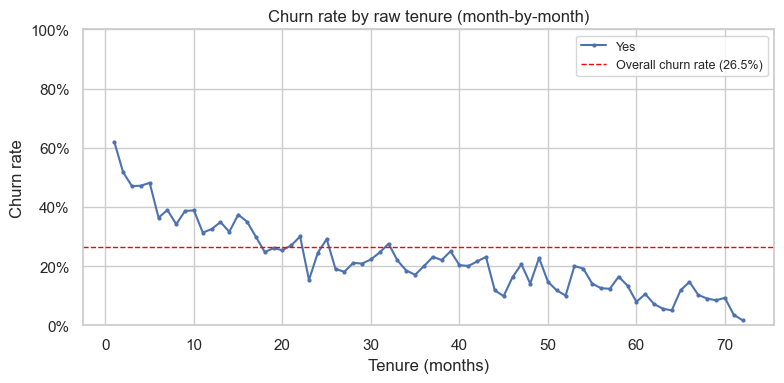

In [27]:
churn_by_tenure = df.groupby("tenure")["Churn"].value_counts(normalize=True).unstack()

f, ax = plt.subplots(figsize=(8, 4))
churn_by_tenure["Yes"].plot(kind="line", ax=ax, marker="o", markersize=2, color="b")
ax.axhline(churn_yes, color="red", linestyle="--", linewidth=1, label=f"Overall churn rate ({churn_yes:.1%})")
ax.legend(loc="upper right", fontsize=9)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate")
ax.set_title("Churn rate by raw tenure (month-by-month)")
plt.tight_layout()
plt.show()

In [28]:
# Chi-square test: does churn rate differ between tenure groups?
tenure_group_counts = df.groupby("Tenure_group", observed=True)["Churn"].value_counts().unstack()
chi2, p_value, dof, expected = chi2_contingency(tenure_group_counts)
print(f"Chi-Square: {chi2:.2f}, p-value: {p_value:.3g} {p_label(p_value)}")

Chi-Square: 959.97, p-value: 7.86e-199 (p < 0.001, significant)


**Observation:** churn is highest in the first 6 months, especially in month 1. It stays above average until about month 18 and only drops clearly below average close to month 24.

#### Q2c. Contract × tenure interaction

Does "new customers churn more" apply to all contract types, or only to month-to-month?

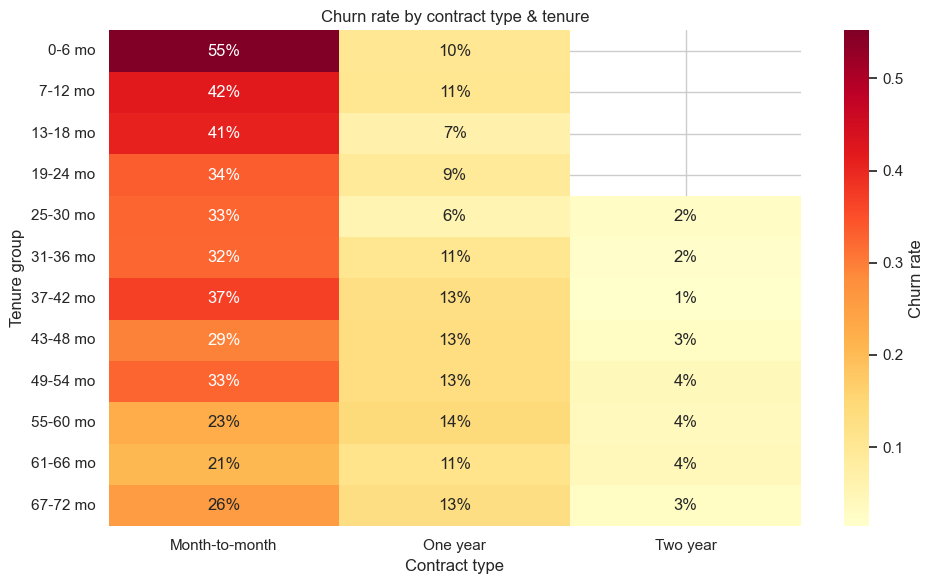

In [29]:
churn_by_contract_tenure = df.groupby(["Contract", "Tenure_group"], observed=True)["Churn"].value_counts(normalize=True).unstack()
churn_matrix = churn_by_contract_tenure["Yes"].unstack(level="Contract")

plt.figure(figsize=(10, 6))
sns.heatmap(churn_matrix, cmap="YlOrRd", annot=True, fmt=".0%", cbar_kws={"label": "Churn rate"})
plt.title("Churn rate by contract type & tenure")
plt.xlabel("Contract type")
plt.ylabel("Tenure group")
plt.tight_layout()
plt.show()

**Observation:** the "new customers churn more" pattern only applies to month-to-month: 55% churn in the first 6 months, ~41% by months 13–18, then around 30%. For one- and two-year contracts churn stays low (under 15%) but goes slightly *up* over time, not down.

**Business implication:** different actions per contract type:
- **Month-to-month:** focus on the first 6 months and continue until about month 18: onboarding call in month 1, small rewards at months 3, 6 and 12, and contact when there are warning signs.
- **One- and two-year:** contact customers before the renewal date with a check-in or a renewal offer.

### Q3. Is there a gender difference in churn rate?

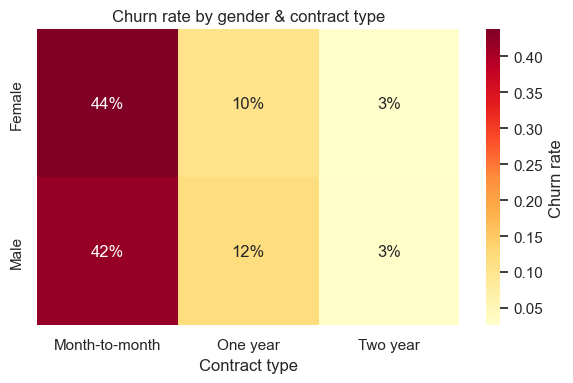


Chi-Square: 0.48, p-value: 0.4866 (not significant)


In [30]:
churn_by_gender_contract = df.groupby(["gender", "Contract"])["Churn"].value_counts(normalize=True).unstack()
gender_contract_matrix = churn_by_gender_contract["Yes"].unstack(level="Contract")

plt.figure(figsize=(6, 4))
sns.heatmap(gender_contract_matrix, cmap="YlOrRd", annot=True, fmt=".0%", cbar_kws={"label": "Churn rate"})
plt.title("Churn rate by gender & contract type")
plt.xlabel("Contract type")
plt.ylabel("")
plt.tight_layout()
plt.show()


gender_counts = df.groupby("gender")["Churn"].value_counts().unstack()
chi2, p_value, dof, expected = chi2_contingency(gender_counts)
print(f"\nChi-Square: {chi2:.2f}, p-value: {p_value:.4f} {p_label(p_value)}")

**Observation:** men and women churn at almost the same rate in every contract type. The chi-square test shows no significant difference (p = 0.49), so gender is not useful for targeting.

### Q4. Does payment method affect churn?

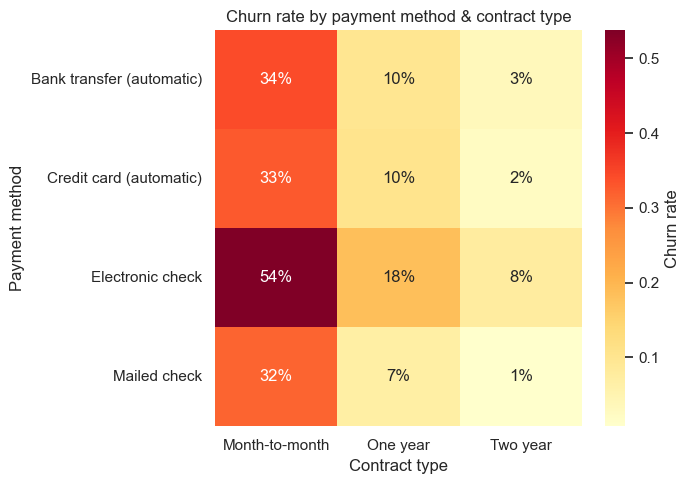

In [31]:
# churn_by_payment feeds the "Visual recap" panel further down
churn_by_payment = df.groupby("PaymentMethod")["Churn"].value_counts(normalize=True).unstack()

churn_by_payment_contract = df.groupby(["PaymentMethod", "Contract"])["Churn"].value_counts(normalize=True).unstack()
payment_contract_matrix = churn_by_payment_contract["Yes"].unstack(level="Contract")

plt.figure(figsize=(7, 5))
sns.heatmap(payment_contract_matrix, cmap="YlOrRd", annot=True, fmt=".0%", cbar_kws={"label": "Churn rate"})
plt.title("Churn rate by payment method & contract type")
plt.xlabel("Contract type")
plt.ylabel("Payment method")
plt.tight_layout()
plt.show()

In [32]:
# Overall test: is churn rate independent of payment method?
print(churn_by_payment)
print()

payment_counts = df.groupby("PaymentMethod")["Churn"].value_counts().unstack()
chi2, p_value, dof, expected = chi2_contingency(payment_counts)
print(f"Chi-Square: {chi2:.2f}, p-value: {p_value:.3g} {p_label(p_value)}")

Churn                            No       Yes
PaymentMethod                                
Bank transfer (automatic)  0.832902  0.167098
Credit card (automatic)    0.847569  0.152431
Electronic check           0.547146  0.452854
Mailed check               0.808933  0.191067

Chi-Square: 648.14, p-value: 3.68e-140 (p < 0.001, significant)


In [33]:
# Is electronic check's elevated churn real within each contract tier, or just noise?
for contract in ["Month-to-month", "One year", "Two year"]:
    sub = df[df["Contract"] == contract]
    payment_counts = sub.groupby("PaymentMethod")["Churn"].value_counts().unstack()
    chi2, p_value, dof, expected = chi2_contingency(payment_counts)
    print(f"{contract}: chi2={chi2:.2f}, p-value={p_value:.3g} {p_label(p_value)}")

Month-to-month: chi2=176.65, p-value=4.67e-38 (p < 0.001, significant)
One year: chi2=25.83, p-value=1.03e-05 (p < 0.001, significant)
Two year: chi2=21.85, p-value=7.02e-05 (p < 0.001, significant)


**Observation:** electronic check customers churn the most overall (45%) and also within each contract type: 54% (month-to-month), 18% (one-year), 8% (two-year), always higher than the other payment methods. The test is significant in every contract type, so payment method has its own effect, separate from contract type.

**Business implication:** encourage electronic check customers to switch to automatic payment (bank transfer or credit card). This is an easier change to ask for than a new contract.

### Q5. Does paperless billing affect churn?

In [34]:
churn_by_paperless = df.groupby("PaperlessBilling")["Churn"].value_counts(normalize=True).unstack()
print(churn_by_paperless)

paperless_counts = df.groupby("PaperlessBilling")["Churn"].value_counts().unstack()
chi2, p_value, dof, expected = chi2_contingency(paperless_counts)
print(f"\nChi-Square: {chi2:.2f}, p-value: {p_value:.3g} {p_label(p_value)}")

Churn                   No       Yes
PaperlessBilling                    
No                0.836699  0.163301
Yes               0.664349  0.335651

Chi-Square: 258.28, p-value: 4.07e-58 (p < 0.001, significant)


**Observation:** customers with paperless billing churn about twice as often (33.6% vs 16.3%, p < 0.001). This is probably partly because many of them are month-to-month customers (see Q10), so I treat it as a warning sign, not a cause.

### Q6. Do higher-paying customers churn more or less?

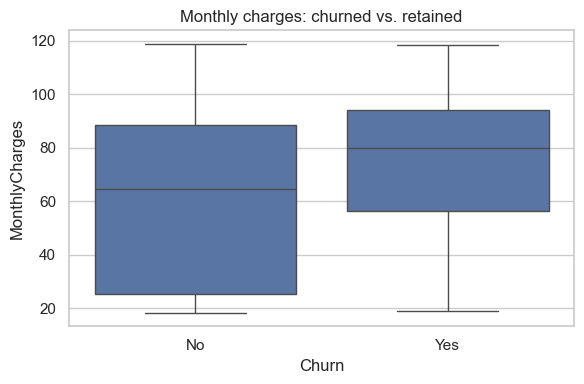

,mean,50%
Churn,,
No,61.265124,64.425
Yes,74.441332,79.650


In [35]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax)
ax.set_title("Monthly charges: churned vs. retained")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q6_charges_by_churn.png", dpi=120)
plt.show()

df.groupby("Churn")["MonthlyCharges"].describe()[["mean", "50%"]]

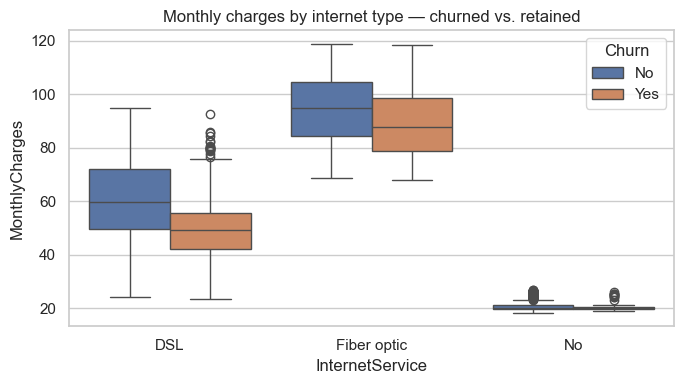

In [36]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x="InternetService", y="MonthlyCharges", hue="Churn", ax=ax)
ax.set_title("Monthly charges by internet type — churned vs. retained")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q6_charges_by_internet_churn.png", dpi=120)
plt.show()

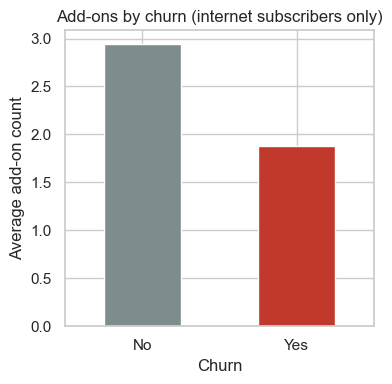

In [37]:
addon_by_churn = df[df["InternetService"] != "No"].groupby("Churn")["Addon_count"].mean()

fig, ax = plt.subplots(figsize=(4, 4))
addon_by_churn.plot(kind="bar", ax=ax, color=["#7f8c8d", "#c0392b"])
ax.set_ylabel("Average add-on count")
ax.set_title("Add-ons by churn (internet subscribers only)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q6_addons_by_churn.png", dpi=120)
plt.show()

**Observation:** overall, churned customers pay more per month (median $80 vs $64). But within each internet type they pay slightly *less* (DSL: $49 vs $60, Fiber: $88 vs $95). The overall difference comes from churners being mostly on the more expensive fiber plan (see Q7). They also have fewer add-ons (1.9 vs 2.9 on average). So the problem looks like value for money, not price alone.

*(No chi-square test here, because monthly charges is a number, not a category.)*

### Q7. Does internet service type affect churn?

In [38]:
churn_by_internet = df.groupby("InternetService")["Churn"].value_counts(normalize=True).unstack()
print(churn_by_internet)

Churn                  No       Yes
InternetService                    
DSL              0.810409  0.189591
Fiber optic      0.581072  0.418928
No               0.925950  0.074050


**Observation:** phone-only customers (no internet) churn the least (7%). Fiber optic customers churn much more than DSL (42% vs 19%), even though fiber is the premium product. This data can't explain why (price? service quality?), so it is a question for the product/network team.

#### Visual recap: churn rate by single driver

Contract, payment method, billing and internet type side by side.

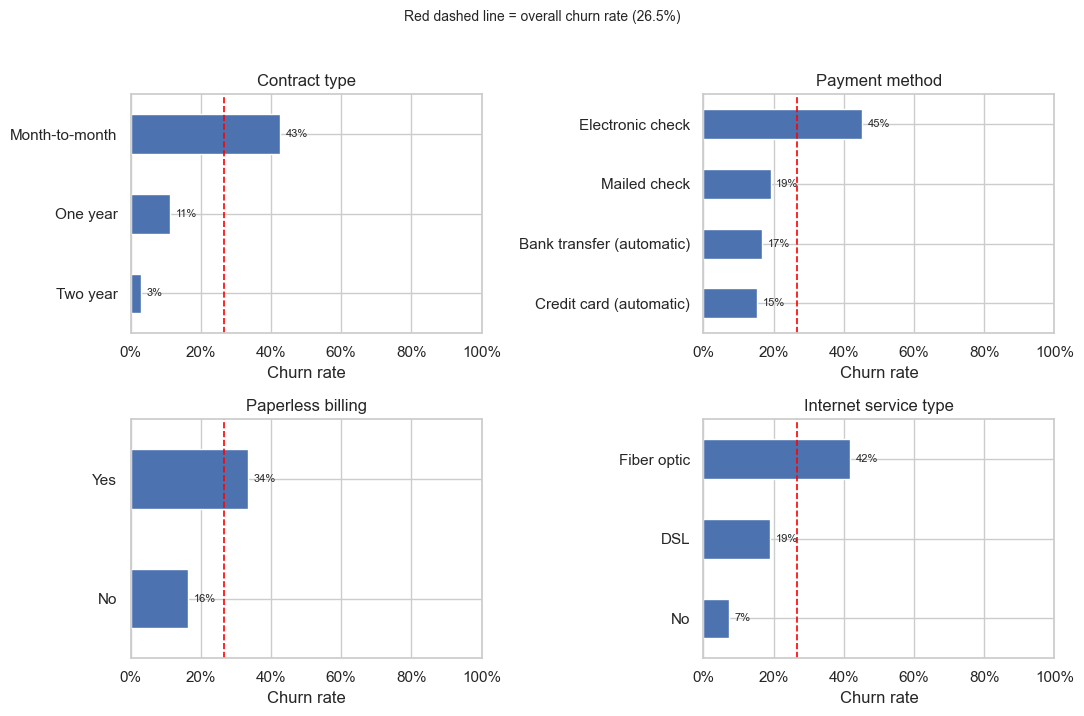

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

panels = [
    (churn_by_contract["Yes"].sort_values(), "Contract type", axes[0, 0]),
    (churn_by_payment["Yes"].sort_values(), "Payment method", axes[0, 1]),
    (churn_by_paperless["Yes"].sort_values(), "Paperless billing", axes[1, 0]),
    (churn_by_internet["Yes"].sort_values(), "Internet service type", axes[1, 1]),
]

for series, title, ax in panels:
    series.plot(kind="barh", ax=ax, color="b")
    ax.axvline(churn_yes, color="red", linestyle="--", linewidth=1.2)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_xlabel("Churn rate")
    ax.set_ylabel("")
    ax.set_title(title)
    for bar in ax.patches:
        width = bar.get_width()
        ax.annotate(f"{width:.0%}", xy=(width, bar.get_y() + bar.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", ha="left", va="center", fontsize=8)

fig.suptitle(f"Red dashed line = overall churn rate ({churn_yes:.1%})", y=1.02, fontsize=10)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q_single_driver_panel.png", dpi=120, bbox_inches="tight")
plt.show()

### Q8. Does bundling more add-on services reduce churn?

Customers without internet automatically have 0 add-ons, and they rarely churn. Including them would distort the result, so this question uses internet customers only. Both versions are printed below for comparison.

In [40]:
internet_customers = df[df["InternetService"] != "No"]

addon_naive = df.groupby("Addon_count")["Churn"].value_counts(normalize=True).unstack()
addon_scoped = internet_customers.groupby("Addon_count")["Churn"].value_counts(normalize=True).unstack()

print("All customers (unscoped — misleading, kept here to show why it's wrong):")
print(addon_naive)
print("\nInternet subscribers only (correct scope):")
print(addon_scoped)

All customers (unscoped — misleading, kept here to show why it's wrong):
Churn              No       Yes
Addon_count                    
0            0.785940  0.214060
1            0.542443  0.457557
2            0.641820  0.358180
3            0.726297  0.273703
4            0.776995  0.223005
5            0.875657  0.124343
6            0.947183  0.052817

Internet subscribers only (correct scope):
Churn              No       Yes
Addon_count                    
0            0.477633  0.522367
1            0.542443  0.457557
2            0.641820  0.358180
3            0.726297  0.273703
4            0.776995  0.223005
5            0.875657  0.124343
6            0.947183  0.052817


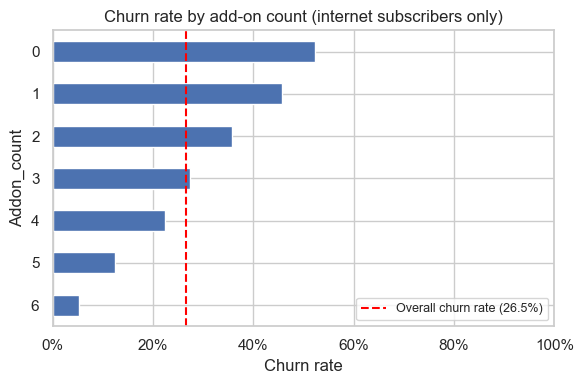

In [41]:
f, ax = plt.subplots(figsize=(6, 4))
addon_scoped["Yes"].sort_values(ascending=True).plot(kind="barh", ax=ax, color="b", label="_nolegend_")
ax.axvline(churn_yes, color="red", linestyle="--", linewidth=1.5, label=f"Overall churn rate ({churn_yes:.1%})")
ax.legend(loc="lower right", fontsize=9)
ax.set_xlabel("Churn rate")
ax.set_title("Churn rate by add-on count (internet subscribers only)")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q8_churn_by_addons.png", dpi=120)
plt.show()

**Observation:** with all customers, 0 add-ons shows *lower* churn than 1 add-on, because the 0 group is mostly phone-only customers. With internet customers only, the pattern is clear: churn falls from 52% (0 add-ons) to 5% (all 6). More add-ons, more loyal customers.

### Q9. Correlation overview (numeric features)

A quick check that the numeric columns confirm the patterns above.

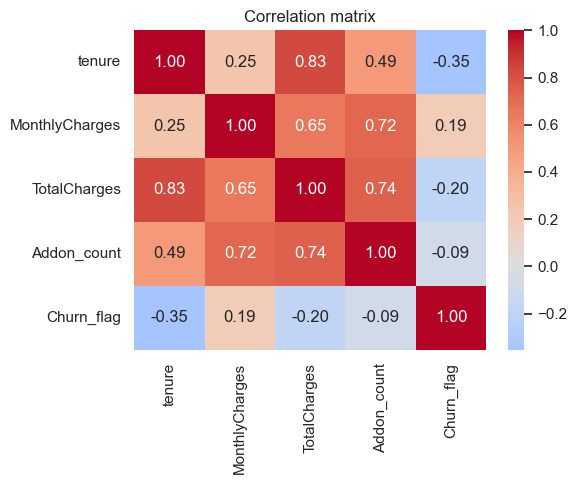

In [42]:
corr_df = df[["tenure", "MonthlyCharges", "TotalCharges", "Addon_count"]].copy()
corr_df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/correlation_heatmap.png", dpi=120)
plt.show()

**Observation:** longer tenure → lower churn (-0.35); higher monthly charges → higher churn (+0.19). Total charges shows lower churn (-0.20) only because it grows with tenure: customers who stayed longer have paid more in total. Add-on count looks weak here (-0.09) because phone-only customers are included; Q8 shows the correct picture.

### Q10. Which binary flags correlate most with churn?

In [43]:
binary_cols = [
    "Partner", "Dependents", "PhoneService", "MultipleLines",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "PaperlessBilling", "SeniorCitizen", "Churn",
]

df_numeric = df.copy()
for col in binary_cols:
    df_numeric[col] = df_numeric[col].map({"Yes": 1, "No": 0})

churn_corr = df_numeric[binary_cols].corr()["Churn"].drop("Churn").sort_values(ascending=False)
churn_corr

PaperlessBilling    0.191825
SeniorCitizen       0.150889
StreamingTV         0.063228
StreamingMovies     0.061382
MultipleLines       0.040102
PhoneService        0.011942
DeviceProtection   -0.066160
OnlineBackup       -0.082255
Partner            -0.150448
Dependents         -0.164221
TechSupport        -0.164674
OnlineSecurity     -0.171226
Name: Churn, dtype: float64

**Observation:** paperless billing (+0.19) and senior citizens (+0.15) are linked to higher churn. Online security, tech support, dependents and partner are linked to lower churn (about -0.15 to -0.17). Phone service and multiple lines have almost no link.

Some of these overlap (for example, paperless billing with month-to-month contracts), so they should not be treated as separate causes.

#### Q10b. Raw churn rates for the top-correlated flags

In [44]:
for col in ["SeniorCitizen", "OnlineSecurity", "TechSupport", "Partner", "Dependents"]:
    print(f"--- {col} ---")
    print(df.groupby(col)["Churn"].value_counts(normalize=True).unstack())
    print()

--- SeniorCitizen ---
Churn                No       Yes
SeniorCitizen                    
No             0.763938  0.236062
Yes            0.583187  0.416813

--- OnlineSecurity ---
Churn                 No       Yes
OnlineSecurity                    
No              0.686704  0.313296
Yes             0.853888  0.146112

--- TechSupport ---
Churn              No       Yes
TechSupport                    
No           0.688138  0.311862
Yes          0.848337  0.151663

--- Partner ---
Churn          No       Yes
Partner                    
No       0.670420  0.329580
Yes      0.803351  0.196649

--- Dependents ---
Churn             No       Yes
Dependents                    
No          0.687209  0.312791
Yes         0.845498  0.154502



**Observation:** senior citizens churn at 42% vs 24%. Customers with online security churn at 15% vs 31% without it, and with tech support at 15% vs 31%. Customers with a partner (20% vs 33%) or dependents (15% vs 31%) churn less.

### Q11. What does the highest-risk segment look like?

Combine the strongest factors into one group and compare it with the overall churn rate.

I did not add electronic check to the main group: churn would be higher (61.8%), but the group would be too small (346 customers) for a campaign. It is shown below as a "contact first" sub-group.

Baseline churn rate:            26.5%
High-risk segment churn rate:   53.6%
High-risk segment size:         670 customers (9.5% of base)
Monthly billing currently in this segment:  $39,438/mo
Gap vs. baseline churn rate:                 27.0 pts

Narrower segment (+ electronic check): 61.8% churn, 346 customers (4.9% of base)


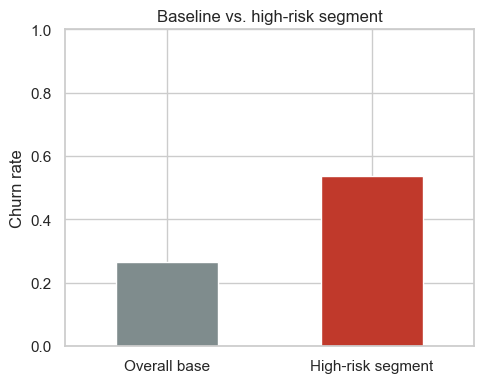

In [45]:
baseline = churn_yes

high_risk = df[
    (df["Contract"] == "Month-to-month")
    & (df["Addon_count"] == 0)
    & (df["InternetService"] != "No")  # exclude no-internet customers — same scoping fix as Q8
]
high_risk_rate = (high_risk["Churn"] == "Yes").mean()

print(f"Baseline churn rate:            {baseline:.1%}")
print(f"High-risk segment churn rate:   {high_risk_rate:.1%}")
print(f"High-risk segment size:         {len(high_risk)} customers ({len(high_risk) / len(df):.1%} of base)")

monthly_at_risk = high_risk["MonthlyCharges"].sum()
print(f"Monthly billing currently in this segment:  ${monthly_at_risk:,.0f}/mo")
print(f"Gap vs. baseline churn rate:                 {(high_risk_rate - baseline) * 100:.1f} pts")

high_risk_narrow = high_risk[high_risk["PaymentMethod"] == "Electronic check"]
high_risk_narrow_rate = (high_risk_narrow["Churn"] == "Yes").mean()
print(f"\nNarrower segment (+ electronic check): {high_risk_narrow_rate:.1%} churn, "
      f"{len(high_risk_narrow)} customers ({len(high_risk_narrow) / len(df):.1%} of base)")

fig, ax = plt.subplots(figsize=(5, 4))
pd.Series({"Overall base": baseline, "High-risk segment": high_risk_rate}).plot(
    kind="bar", ax=ax, color=["#7f8c8d", "#c0392b"]
)
ax.set_ylabel("Churn rate")
ax.set_title("Baseline vs. high-risk segment")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q11_high_risk_segment.png", dpi=120)
plt.show()

**Observation:** month-to-month customers with internet and no add-ons churn at 53.6%, double the 26.5% average. That is 670 customers (9.5%) and ~$39K of monthly billing. Contract and internet type are known at sign-up, and add-ons can be checked in the first months, so this group can be found early.

## 6. Summary of findings

- **Contract type is the biggest driver.** Month-to-month: 43% churn vs 11% (one-year) and 3% (two-year), χ² = 1184.60, p < 0.001.
- **The first 6–18 months are the riskiest, but only for month-to-month customers.** Term contracts stay low but rise slightly over time (Q2c).
- **Gender has no effect** (p = 0.49).
- **Electronic check is a separate risk factor:** 45% churn overall (χ² = 648.14, p < 0.001) and the highest in every contract type (Q4).
- **Paperless billing** is linked to higher churn (33.6% vs 16.3%), probably partly through month-to-month contracts (Q5).
- **Churners pay more per month overall, but less within the same internet type.** The difference comes from fiber customers (Q6).
- **Fiber optic churns much more than DSL** (42% vs 19%). The reason is unknown and needs follow-up (Q7).
- **More add-ons, less churn:** 52% with 0 add-ons → 5% with all 6 (internet customers only, Q8).
- **Online security, tech support, partner and dependents** are linked to lower churn; **senior citizens** to higher churn (Q10).
- **Highest-risk group:** month-to-month + internet + no add-ons: 53.6% churn, 670 customers, ~$39K/month. Adding electronic check: 61.8% churn, 346 customers (Q11).

**Suggested action:** retention offers (contract-upgrade discount, free add-on trial, onboarding call) for new month-to-month customers with no add-ons. Follow up the fiber churn gap with the network team, and the paperless billing link with the billing team.